## 1 · Imports & global settings

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import time

np.set_printoptions(precision=4, suppress=True)

## 2 · File paths

In [40]:
INPUT_CSV   = "input_min_conso.csv"
NEURON_CSV  = "neuron.csv"
SYN_EXC_CSV = "excitation20.csv"
SYN_INH_CSV = "inhibition20.csv"

## 3 · Hyperparameters

In [41]:
# ── Reproducibility ──────────────────────────────────────
SEED = 42

# ── Problème XOR ─────────────────────────────────────────
# Classe 1 : (x>0 ET y>0) OU (x<0 ET y<0)  → diagonale ↗
# Classe 0 : (x>0 ET y<0) OU (x<0 ET y>0)  → diagonale ↘
# Frontière = axes x=0 et y=0
# Impossible à séparer avec une droite → réseau obligatoire

# ── Dataset ──────────────────────────────────────────────
N_TRAIN  = 1200   # points uniformes dans [-1,1]²
N_TEST   = 400
MARGIN   = 0.05   # exclure les points trop près des axes (ambigus)

# ── Architecture ─────────────────────────────────────────
INPUT_DIM           = 2
BRANCH_HIDDEN_SIZES = [8, 8]   # petit réseau suffisant pour XOR

# ── Search ───────────────────────────────────────────────
N_RESTARTS_PER_BRANCH = 8
MAX_PASSES            = 6
MARGIN_SCALE          = 5e-6
FREQ_MERGE_TOL        = 1000.0

# ── Hardware options ─────────────────────────────────────
ALLOW_ZERO_SYNAPSES            = True
ZERO_SYNAPSE_INIT_PROB         = 0.15
USE_SMALLER_WIDTHS_DEEP_LAYERS = True
DEEP_EXC_MAX                   = 1.04    # ~1/3 de la plage exc pour couches profondes
DEEP_INH_MAX                   = 0.499   # ~1/2 de la plage inh

# ── Score ────────────────────────────────────────────────
IMBALANCE_PENALTY_SCALE = 0.15

# ── Branch B ─────────────────────────────────────────────
ERROR_BOOST       = 3.0
LOW_MARGIN_BOOST  = 2.0
MARGIN_TARGET_HZ  = 4000.0
MAX_SAMPLE_WEIGHT = 6.0

# ── Alpha ────────────────────────────────────────────────
ALPHA_CANDIDATES = np.array([0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0])

## 4 · Utility functions

In [42]:
def progress_bar(current, total, prefix="", suffix="", bar_len=30):
    filled = int(bar_len * current / total)
    bar    = "█" * filled + "░" * (bar_len - filled)
    pct    = int(100 * current / total)
    sys.stdout.write(f"\r  {prefix}[{bar}] {current}/{total} {pct}%  {suffix}")
    sys.stdout.flush()
    if current == total:
        sys.stdout.write("\n"); sys.stdout.flush()

## 5 · CSV readers

In [43]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if "Parameter" not in df.columns:
        raise ValueError(f"{csv_path}: missing 'Parameter' column")
    data_cols = [c for c in df.columns if c not in ["Parameter", "Unnamed: 1"]]

    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df["Parameter"] == row_name, data_cols]
        if row.empty:
            raise ValueError(f"Row '{row_name}' not found in {csv_path}")
        values = pd.to_numeric(row.iloc[0], errors="coerce").to_numpy(dtype=float)
        if (not allow_non_numeric) and np.isnan(values).any():
            raise ValueError(f"Row '{row_name}' contains non-numeric values")
        return values

    return get_row

def get_clean_rows(reader, row_names):
    rows    = [reader(name, allow_non_numeric=True) for name in row_names]
    stacked = np.vstack(rows)
    mask    = np.all(np.isfinite(stacked), axis=0)
    return [r[mask] for r in rows], mask

## 6 · Interpolation helpers

In [44]:
def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, dtype=float), xp, fp, left=fp[0], right=fp[-1])

def interp2d_bilinear_vec(x, y, x_axis, y_axis, z_grid):
    x  = np.clip(np.asarray(x, dtype=float), x_axis[0], x_axis[-1])
    y  = np.clip(np.asarray(y, dtype=float), y_axis[0], y_axis[-1])
    ix = np.clip(np.searchsorted(x_axis, x, side="right") - 1, 0, len(x_axis) - 2)
    iy = np.clip(np.searchsorted(y_axis, y, side="right") - 1, 0, len(y_axis) - 2)
    x1, x2 = x_axis[ix], x_axis[ix + 1]
    y1, y2 = y_axis[iy], y_axis[iy + 1]
    tx = np.where(x2 == x1, 0.0, (x - x1) / (x2 - x1))
    ty = np.where(y2 == y1, 0.0, (y - y1) / (y2 - y1))
    return (z_grid[ix,   iy  ] * (1-tx) * (1-ty) +
            z_grid[ix+1, iy  ] * tx     * (1-ty) +
            z_grid[ix,   iy+1] * (1-tx) * ty     +
            z_grid[ix+1, iy+1] * tx     * ty)

def strictly_monotonic_branch(x, y):
    im = int(np.argmax(y))
    x_m, y_m = np.asarray(x[:im+1], dtype=float), np.asarray(y[:im+1], dtype=float)
    order = np.argsort(x_m)
    return x_m[order], y_m[order]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, dtype=float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups], dtype=float)

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))] for v in np.asarray(values, dtype=float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            vals = Y_all[mask]
            if len(vals) == 0:
                raise ValueError(f"Missing point W={w}, F={f}")
            z_grid[i, j] = np.mean(vals)
    return W_unique, F_axis, z_grid

## 7 · Load hardware tables

In [45]:
inp = read_cadence_rows(INPUT_CSV)
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(inp("Vex"), inp("Fspikes"))

neuro = read_cadence_rows(NEURON_CSV)
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(neuro("Iex"), neuro("Fspikes"))

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ["W2", "Fpre", "Ipost"])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, freq_tol=FREQ_MERGE_TOL)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ["W2", "Fpre", "Ipost"])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, freq_tol=FREQ_MERGE_TOL)

V_MIN = float(INPUT_V_AXIS[0])
V_MAX = float(INPUT_V_AXIS[-1])

print(f"Input  V : {V_MIN*1e3:.0f} mV → {V_MAX*1e3:.0f} mV")
print(f"Neuron I : {NEURON_I_AXIS[0]*1e12:.1f} pA → {NEURON_I_AXIS[-1]*1e12:.0f} pA")
print(f"Exc W ({len(W_EXC_AXIS)} valeurs µm): {W_EXC_AXIS}")
print(f"Inh W ({len(W_INH_AXIS)} valeurs µm): {W_INH_AXIS}")

Input  V : -100 mV → 100 mV
Neuron I : 3.0 pA → 1000 pA
Exc W (20 valeurs µm): [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]
Inh W (20 valeurs µm): [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]


## 8 · Architecture & forward pass

In [46]:
BRANCH_LAYER_SIZES = [INPUT_DIM] + BRANCH_HIDDEN_SIZES + [2]
print(f"Architecture : {BRANCH_LAYER_SIZES}")
print(f"Problème     : XOR — classe 1 si quadrant NE ou SW, classe 0 sinon")

def input_f_of_v(Vin_V):
    return interp_clip(Vin_V, INPUT_V_AXIS, INPUT_F_AXIS)

def neuron_f_of_i(Iin_A):
    return interp_clip(Iin_A, NEURON_I_AXIS, NEURON_F_AXIS)

def get_layer_candidates(layer_idx):
    exc_axis = W_EXC_AXIS
    inh_axis = W_INH_AXIS
    if USE_SMALLER_WIDTHS_DEEP_LAYERS and layer_idx >= 1:
        exc_f = exc_axis[exc_axis <= DEEP_EXC_MAX]
        inh_f = inh_axis[inh_axis <= DEEP_INH_MAX]
        exc_axis = exc_f if len(exc_f) > 0 else W_EXC_AXIS
        inh_axis = inh_f if len(inh_f) > 0 else W_INH_AXIS
    cand = []
    if ALLOW_ZERO_SYNAPSES:
        cand.append((0, 0.0))
    cand += [(+1, float(w)) for w in exc_axis]
    cand += [(-1, float(w)) for w in inh_axis]
    return cand

ALL_CANDIDATES_PER_LAYER = [
    get_layer_candidates(l) for l in range(len(BRANCH_LAYER_SIZES) - 1)
]

def layer_forward_batch(Fin_batch, sign_matrix, width_matrix):
    B, N = Fin_batch.shape
    M    = sign_matrix.shape[1]
    F = np.broadcast_to(Fin_batch[:, :, None],    (B, N, M))
    W = np.broadcast_to(width_matrix[None, :, :], (B, N, M))
    S = np.broadcast_to(sign_matrix[None, :, :],  (B, N, M))
    Iexc = interp2d_bilinear_vec(W, F, W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID)
    Iinh = interp2d_bilinear_vec(W, F, W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID)
    Iconn = np.where(S == 1, Iexc, np.where(S == -1, -Iinh, 0.0))
    return neuron_f_of_i(np.sum(Iconn, axis=1))

def network_forward_batch(Vin_batch, sign_matrices, width_matrices):
    F = input_f_of_v(Vin_batch)
    for sm, wm in zip(sign_matrices, width_matrices):
        F = layer_forward_batch(F, sm, wm)
    return F

Architecture : [2, 8, 8, 2]
Problème     : XOR — classe 1 si quadrant NE ou SW, classe 0 sinon


## 9 · Dataset generation — XOR

In [47]:
def label_xor(X):
    """
    XOR : classe 1 si x et y ont le même signe (quadrant NE ou SW).
    On exclut les points dans la bande |x|<MARGIN ou |y|<MARGIN
    pour éviter les cas ambigus sur les axes.
    """
    x, y = X[:, 0], X[:, 1]
    same_sign = ((x > 0) & (y > 0)) | ((x < 0) & (y < 0))
    return same_sign.astype(np.int32)

def make_dataset(n, seed=0, exclude_margin=True):
    rng = np.random.default_rng(seed)
    pts = []
    while len(pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 2, 2)).astype(np.float32)
        if exclude_margin:
            mask = (np.abs(batch[:, 0]) > MARGIN) & (np.abs(batch[:, 1]) > MARGIN)
            batch = batch[mask]
        pts.append(batch)
    X = np.vstack(pts)[:n]
    return X, label_xor(X)

def xy_to_voltage(X):
    """
    Encodage direct (x, y) → tensions hardware.
    Le réseau doit apprendre lui-même à combiner x et y
    pour détecter le signe de x*y — c'est le cœur du XOR.
    """
    X = np.asarray(X, dtype=np.float32)
    return (V_MIN + (X + 1.0) * (V_MAX - V_MIN) / 2.0).astype(np.float32)

def make_datasets():
    X_train, y_train = make_dataset(N_TRAIN, seed=SEED)
    X_test,  y_test  = make_dataset(N_TEST,  seed=SEED + 1)
    # Équilibrage des classes
    rng = np.random.default_rng(SEED)
    idx = np.arange(len(X_train)); rng.shuffle(idx)
    X_train, y_train = X_train[idx], y_train[idx]
    V_train = xy_to_voltage(X_train)
    V_test  = xy_to_voltage(X_test)
    print(f"Train : {len(y_train)} pts | classe1={y_train.sum()} ({y_train.mean()*100:.0f}%) "
          f"classe0={(1-y_train).sum()} ({(1-y_train).mean()*100:.0f}%)")
    print(f"Test  : {len(y_test)}  pts | classe1={y_test.sum()} ({y_test.mean()*100:.0f}%) "
          f"classe0={(1-y_test).mean()*100:.0f}%)")
    return X_train, y_train, X_test, y_test, V_train, V_test

## 10 · Metrics & evaluation

In [48]:
def normalize_weights_per_class(sample_weights, y_true):
    w = np.asarray(sample_weights, dtype=float).copy()
    for cls in [0, 1]:
        mask = (np.asarray(y_true) == cls)
        if np.any(mask):
            m = np.mean(w[mask])
            if m > 0: w[mask] /= m
    return w

def weighted_mean(values, weights):
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    d = np.sum(weights)
    return 0.0 if d <= 0 else float(np.sum(weights * values) / d)

def compute_true_margin(Fout, y_true):
    y = np.asarray(y_true, int)
    idx = np.arange(len(y))
    return Fout[idx, y] - Fout[idx, 1 - y]

def evaluate_outputs(Fout, y_true, sample_weights=None):
    y_true = np.asarray(y_true, int)
    preds  = np.argmax(Fout, axis=1)
    if sample_weights is None:
        sample_weights = np.ones(len(y_true), float)
    else:
        sample_weights = normalize_weights_per_class(sample_weights, y_true)
    mask0, mask1 = (y_true == 0), (y_true == 1)
    w0, w1 = sample_weights[mask0], sample_weights[mask1]
    acc0 = weighted_mean((preds[mask0] == 0).astype(float), w0) if np.any(mask0) else 0.0
    acc1 = weighted_mean((preds[mask1] == 1).astype(float), w1) if np.any(mask1) else 0.0
    bal_acc    = 0.5 * (acc0 + acc1)
    margin0    = weighted_mean(Fout[mask0, 0] - Fout[mask0, 1], w0) if np.any(mask0) else 0.0
    margin1    = weighted_mean(Fout[mask1, 1] - Fout[mask1, 0], w1) if np.any(mask1) else 0.0
    bal_margin = 0.5 * (margin0 + margin1)
    score = bal_acc + MARGIN_SCALE * bal_margin - IMBALANCE_PENALTY_SCALE * abs(acc0 - acc1)
    return {"preds": preds, "Fout": Fout,
            "acc0": acc0, "acc1": acc1,
            "bal_acc": bal_acc, "bal_margin": bal_margin, "score": score}

def evaluate_network(Vin, y_true, signs, widths, sample_weights=None):
    return evaluate_outputs(network_forward_batch(Vin, signs, widths), y_true, sample_weights)

def print_results(label, m):
    print(f"\n=== {label} ===")
    print(f"  acc classe 0 = {m['acc0']:.4f}  |  acc classe 1 = {m['acc1']:.4f}")
    print(f"  balanced acc = {m['bal_acc']:.4f}")
    print(f"  margin       = {m['bal_margin']*1e-3:.2f} kHz")
    print(f"  score        = {m['score']:.6f}")

## 11 · Random network & coordinate search

In [49]:
def random_network(layer_sizes, rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:])):
        s = rng.choice([-1, 0, 1], size=(n_in, n_out),
                       p=[(1-ZERO_SYNAPSE_INIT_PROB)/2,
                          ZERO_SYNAPSE_INIT_PROB,
                          (1-ZERO_SYNAPSE_INIT_PROB)/2]) if ALLOW_ZERO_SYNAPSES             else rng.choice([-1, 1], size=(n_in, n_out))
        w          = np.zeros((n_in, n_out))
        cands      = ALL_CANDIDATES_PER_LAYER[li]
        exc_only   = [c[1] for c in cands if c[0] ==  1]
        inh_only   = [c[1] for c in cands if c[0] == -1]
        for i in range(n_in):
            for j in range(n_out):
                if   s[i,j] ==  1: w[i,j] = rng.choice(exc_only)
                elif s[i,j] == -1: w[i,j] = rng.choice(inh_only)
        signs.append(s); widths.append(w)
    return signs, widths

def coordinate_search_branch(V_train, y_train, V_val, y_val, layer_sizes,
                              sample_weights_train=None,
                              n_restarts=N_RESTARTS_PER_BRANCH,
                              max_passes=MAX_PASSES,
                              seed=SEED, branch_name="A"):
    rng       = np.random.default_rng(seed)
    all_conns = [(l, i, j)
                 for l, (n_in, n_out) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:]))
                 for i in range(n_in) for j in range(n_out)]
    n_conns   = len(all_conns)
    best_signs_g = best_widths_g = None
    best_val_score = best_train_score = -1e99
    best_history   = []

    for restart in range(n_restarts):
        print(f"\n{'='*60}\nBRANCH {branch_name} | RESTART {restart+1}/{n_restarts}")
        signs, widths = random_network(layer_sizes, rng)
        tr = evaluate_network(V_train, y_train, signs, widths, sample_weights_train)
        va = evaluate_network(V_val,   y_val,   signs, widths)
        history = [{"pass":0, "tr_bal_acc":tr["bal_acc"], "tr_score":tr["score"],
                    "va_bal_acc":va["bal_acc"], "va_score":va["score"]}]
        print(f"Init | tr_acc={tr['bal_acc']:.4f} score={tr['score']:.6f} | "
              f"va_acc={va['bal_acc']:.4f} score={va['score']:.6f}")
        t0 = time.time()

        for pass_idx in range(max_passes):
            improved   = False
            conn_order = list(all_conns); rng.shuffle(conn_order)
            for conn_num, (l, i, j) in enumerate(conn_order):
                best_s, best_w, best_c = signs[l][i,j], widths[l][i,j], tr["score"]
                for cs, cw in ALL_CANDIDATES_PER_LAYER[l]:
                    if cs == signs[l][i,j] and np.isclose(cw, widths[l][i,j]): continue
                    signs[l][i,j], widths[l][i,j] = cs, cw
                    ctr = evaluate_network(V_train, y_train, signs, widths, sample_weights_train)
                    if ctr["score"] > best_c: best_c, best_s, best_w = ctr["score"], cs, cw
                    signs[l][i,j], widths[l][i,j] = best_s if ctr["score"] > tr["score"] else signs[l][i,j],                                                      best_w if ctr["score"] > tr["score"] else widths[l][i,j]
                    signs[l][i,j], widths[l][i,j] = best_s, best_w  # restore best found
                # apply best
                old_score = tr["score"]
                signs[l][i,j], widths[l][i,j] = best_s, best_w
                if best_c > old_score:
                    tr = evaluate_network(V_train, y_train, signs, widths, sample_weights_train)
                    improved = True
                progress_bar(conn_num+1, n_conns, prefix=f"B{branch_name} ",
                             suffix=f"pass {pass_idx+1} acc={tr['bal_acc']:.4f} {time.time()-t0:.0f}s")
            va = evaluate_network(V_val, y_val, signs, widths)
            history.append({"pass":pass_idx+1, "tr_bal_acc":tr["bal_acc"], "tr_score":tr["score"],
                             "va_bal_acc":va["bal_acc"], "va_score":va["score"]})
            print(f"Pass {pass_idx+1} | tr_acc={tr['bal_acc']:.4f} score={tr['score']:.6f} | "
                  f"va_acc={va['bal_acc']:.4f} score={va['score']:.6f}")
            if not improved: print("Converged"); break

        if (va["score"] > best_val_score or
                (np.isclose(va["score"], best_val_score) and tr["score"] > best_train_score)):
            best_signs_g, best_widths_g = [s.copy() for s in signs], [w.copy() for w in widths]
            best_val_score, best_train_score = va["score"], tr["score"]
            best_history = history

    return best_signs_g, best_widths_g, best_history

## 12 · Residual weights & alpha search

In [50]:
def build_residual_weights(Fout_A, y_true):
    y    = np.asarray(y_true, int)
    preds = np.argmax(Fout_A, axis=1)
    tm    = compute_true_margin(Fout_A, y)
    w     = np.ones(len(y), float)
    w    += ERROR_BOOST * (preds != y).astype(float)
    w    += LOW_MARGIN_BOOST * np.clip((MARGIN_TARGET_HZ - tm) / MARGIN_TARGET_HZ, 0, None)
    return normalize_weights_per_class(np.clip(w, 1.0, MAX_SAMPLE_WEIGHT), y)

def search_best_alpha(FA_tr, FB_tr, y_tr, FA_va, FB_va, y_va, alphas):
    best_alpha = best_tr = best_va = None
    for a in alphas:
        tr = evaluate_outputs(FA_tr + a * FB_tr, y_tr)
        va = evaluate_outputs(FA_va + a * FB_va, y_va)
        print(f"alpha={a:4.2f} | tr_acc={tr['bal_acc']:.4f} score={tr['score']:.6f} | "
              f"va_acc={va['bal_acc']:.4f} score={va['score']:.6f}")
        if best_va is None or va["score"] > best_va["score"]:
            best_alpha, best_tr, best_va = a, tr, va
    return best_alpha, best_tr, best_va

## 13 · Visualisation

In [51]:
def print_network(signs, widths, name="NETWORK"):
    names = (["In->H1"] + [f"H{k}->H{k+1}" for k in range(1,len(signs)-1)]
             + [f"H{len(signs)-1}->Out"])
    print(f"\n=== {name} ===")
    for k, (s, w, ln) in enumerate(zip(signs, widths, names)):
        print(f"  Layer {k+1} [{ln}] {s.shape[0]}->{s.shape[1]}"
              f"  exc={int((s==1).sum())} inh={int((s==-1).sum())} off={int((s==0).sum())}")
        print(f"    signs:\n{s}"); print(f"    widths (µm):\n{w}")

def plot_dataset(X, y, title="Dataset XOR"):
    plt.figure(figsize=(5,5))
    plt.scatter(X[y==0,0], X[y==0,1], s=6, alpha=0.5, c="#e06c75", label="Classe 0 (NW/SE)")
    plt.scatter(X[y==1,0], X[y==1,1], s=6, alpha=0.5, c="#61afef", label="Classe 1 (NE/SW)")
    plt.axhline(0, color="k", lw=1, ls="--"); plt.axvline(0, color="k", lw=1, ls="--")
    plt.xlabel("x"); plt.ylabel("y"); plt.title(title)
    plt.gca().set_aspect("equal"); plt.legend(fontsize=8); plt.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

def plot_history(history, title="Search history"):
    if not history: return
    passes = [h["pass"] for h in history]
    plt.figure(figsize=(7,4))
    plt.plot(passes, [h["tr_bal_acc"] for h in history], "o-", label="Train bal acc")
    plt.plot(passes, [h["va_bal_acc"] for h in history], "s-", label="Test bal acc")
    plt.xlabel("Pass"); plt.ylabel("Balanced accuracy"); plt.title(title)
    plt.ylim(0.4, 1.05); plt.axhline(0.5, color="gray", ls=":", lw=1, label="Aléatoire")
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

def plot_decision_map(signs_A, widths_A, signs_B, widths_B, alpha,
                      X_test=None, y_test=None, resolution=120):
    xs, ys = np.linspace(-1, 1, resolution), np.linspace(-1, 1, resolution)
    XX, YY = np.meshgrid(xs, ys)
    grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))
    FA     = network_forward_batch(grid_V, signs_A, widths_A)
    FB     = network_forward_batch(grid_V, signs_B, widths_B)
    Ftot   = FA + alpha * FB
    pred   = np.argmax(Ftot, axis=1).reshape(XX.shape)
    margin = (Ftot[:,1] - Ftot[:,0]).reshape(XX.shape) * 1e-3

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ax = axes[0]
    ax.contourf(XX, YY, pred, levels=[-0.5, 0.5, 1.5],
                colors=["#e06c7544", "#61afef44"])
    ax.contour(XX, YY, margin, levels=[0], colors="k", linewidths=2)
    ax.axhline(0, color="gray", lw=1, ls="--"); ax.axvline(0, color="gray", lw=1, ls="--")
    if X_test is not None:
        ax.scatter(X_test[y_test==0,0], X_test[y_test==0,1], s=4, c="#e06c75", alpha=0.5)
        ax.scatter(X_test[y_test==1,0], X_test[y_test==1,1], s=4, c="#61afef", alpha=0.5)
    ax.set_title(f"Décision réseau (alpha={alpha:.2f})")
    ax.set_aspect("equal"); ax.grid(True, alpha=0.3)

    ax = axes[1]
    vmax = max(abs(float(margin.min())), abs(float(margin.max())), 1.0)
    cf = ax.contourf(XX, YY, margin, levels=50, cmap="RdYlGn", vmin=-vmax, vmax=vmax)
    plt.colorbar(cf, ax=ax, label="F_classe1 - F_classe0 (kHz)")
    ax.contour(XX, YY, margin, levels=[0], colors="k", linewidths=2)
    ax.axhline(0, color="gray", lw=1, ls="--"); ax.axvline(0, color="gray", lw=1, ls="--")
    ax.set_title("Marge de fréquence"); ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

## 14 · Génération du dataset

Train : 1200 pts | classe1=619 (52%) classe0=581 (48%)
Test  : 400  pts | classe1=209 (52%) classe0=48%)


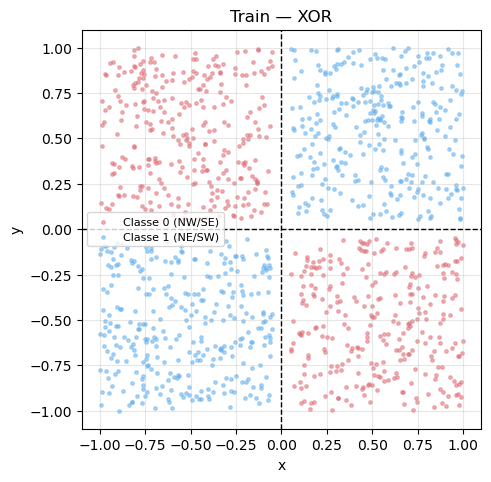

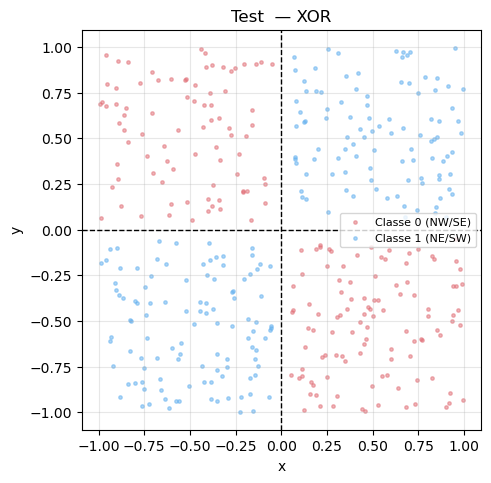

In [52]:
X_train, y_train, X_test, y_test, V_train, V_test = make_datasets()
plot_dataset(X_train, y_train, title="Train — XOR")
plot_dataset(X_test,  y_test,  title="Test  — XOR")

## 15 · Branch A — coordinate search

Architecture Branch A : [2, 8, 8, 2]

BRANCH A | RESTART 1/8
Init | tr_acc=0.5000 score=0.353296 | va_acc=0.5000 score=0.352559
  BA [░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░] 1/96 1%  pass 1 acc=0.5000 0s

  BA [██████████████████████████████] 96/96 100%  pass 1 acc=0.5000 14s
Pass 1 | tr_acc=0.5000 score=0.368977 | va_acc=0.5000 score=0.364820
  BA [██████████████████████████████] 96/96 100%  pass 2 acc=0.5000 29s
Pass 2 | tr_acc=0.5000 score=0.369458 | va_acc=0.5000 score=0.365343
  BA [██████████████████████████████] 96/96 100%  pass 3 acc=0.6834 44s
Pass 3 | tr_acc=0.6834 score=0.626842 | va_acc=0.6483 score=0.580491
  BA [██████████████████████████████] 96/96 100%  pass 4 acc=0.6835 58s
Pass 4 | tr_acc=0.6835 score=0.628194 | va_acc=0.6459 score=0.579493
  BA [██████████████████████████████] 96/96 100%  pass 5 acc=0.6829 72s
Pass 5 | tr_acc=0.6829 score=0.630057 | va_acc=0.6485 score=0.583068
  BA [██████████████████████████████] 96/96 100%  pass 6 acc=0.6829 86s
Pass 6 | tr_acc=0.6829 score=0.630057 | va_acc=0.6485 score=0.583068
Converged

BRANCH A | RESTART 2/8
Init | tr_acc=0.5000 score=0.349350 | va_acc=0.5000 score=0.349177
  BA [██████████████████████████████] 96/96 100%  pas

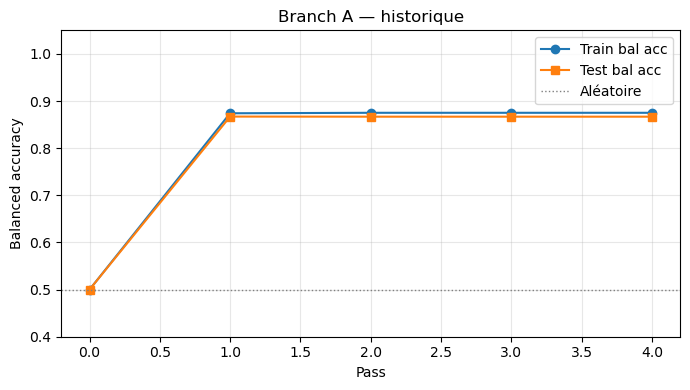

In [53]:
print(f"Architecture Branch A : {BRANCH_LAYER_SIZES}")
signs_A, widths_A, hist_A = coordinate_search_branch(
    V_train, y_train, V_test, y_test,
    layer_sizes=BRANCH_LAYER_SIZES,
    sample_weights_train=None,
    seed=SEED, branch_name="A"
)
print_network(signs_A, widths_A, name="BRANCH A")
mA_tr = evaluate_network(V_train, y_train, signs_A, widths_A)
mA_te = evaluate_network(V_test,  y_test,  signs_A, widths_A)
print_results("BRANCH A — TRAIN", mA_tr)
print_results("BRANCH A — TEST",  mA_te)
plot_history(hist_A, title="Branch A — historique")

## 16 · Residual weights pour Branch B

Poids residuels : min=0.339  max=2.315  mean=1.000


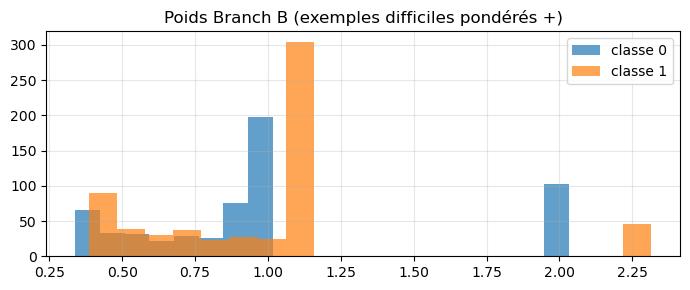

In [54]:
w_B = build_residual_weights(mA_tr["Fout"], y_train)
print(f"Poids residuels : min={w_B.min():.3f}  max={w_B.max():.3f}  mean={w_B.mean():.3f}")
plt.figure(figsize=(7,3))
plt.hist(w_B[y_train==0], bins=20, alpha=0.7, label="classe 0")
plt.hist(w_B[y_train==1], bins=20, alpha=0.7, label="classe 1")
plt.title("Poids Branch B (exemples difficiles pondérés +)"); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 17 · Branch B — coordinate search


BRANCH B | RESTART 1/8
Init | tr_acc=0.5000 score=0.349333 | va_acc=0.5000 score=0.349528
  BB [██████████████████████████████] 96/96 100%  pass 1 acc=0.7882 14s
Pass 1 | tr_acc=0.7882 score=0.739923 | va_acc=0.7257 score=0.654775
  BB [██████████████████████████████] 96/96 100%  pass 2 acc=0.7882 28s
Pass 2 | tr_acc=0.7882 score=0.739923 | va_acc=0.7257 score=0.654775
Converged

BRANCH B | RESTART 2/8
Init | tr_acc=0.5000 score=0.348230 | va_acc=0.5000 score=0.349998
  BB [██████████████████████████████] 96/96 100%  pass 1 acc=0.7867 14s
Pass 1 | tr_acc=0.7867 score=0.741292 | va_acc=0.7150 score=0.648898
  BB [██████████████████████████████] 96/96 100%  pass 2 acc=0.7977 29s
Pass 2 | tr_acc=0.7977 score=0.747856 | va_acc=0.7229 score=0.654380
  BB [██████████████████████████████] 96/96 100%  pass 3 acc=0.7977 43s
Pass 3 | tr_acc=0.7977 score=0.747857 | va_acc=0.7229 score=0.654380
  BB [██████████████████████████████] 96/96 100%  pass 4 acc=0.7977 57s
Pass 4 | tr_acc=0.7977 score=0.

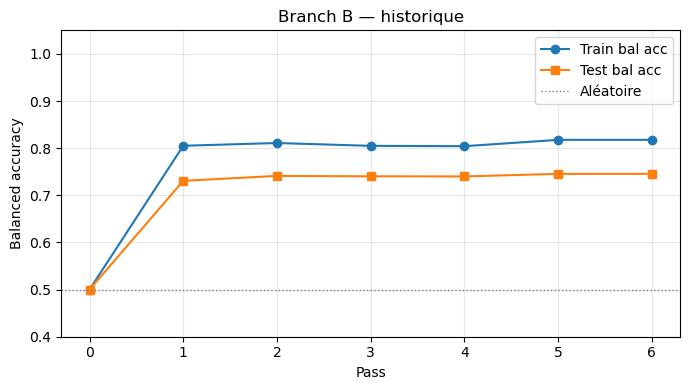

In [55]:
signs_B, widths_B, hist_B = coordinate_search_branch(
    V_train, y_train, V_test, y_test,
    layer_sizes=BRANCH_LAYER_SIZES,
    sample_weights_train=w_B,
    seed=SEED+1000, branch_name="B"
)
print_network(signs_B, widths_B, name="BRANCH B")
mB_tr = evaluate_network(V_train, y_train, signs_B, widths_B)
mB_te = evaluate_network(V_test,  y_test,  signs_B, widths_B)
print_results("BRANCH B — TRAIN", mB_tr)
print_results("BRANCH B — TEST",  mB_te)
plot_history(hist_B, title="Branch B — historique")

## 18 · Alpha search

In [56]:
best_alpha, best_tr, best_te = search_best_alpha(
    mA_tr["Fout"], mB_tr["Fout"], y_train,
    mA_te["Fout"], mB_te["Fout"], y_test,
    ALPHA_CANDIDATES
)
print(f"\nMeilleur alpha = {best_alpha:.4f}")
print_results("COMBINÉ — TRAIN", best_tr)
print_results("COMBINÉ — TEST",  best_te)

alpha=0.00 | tr_acc=0.8751 score=0.866130 | va_acc=0.8668 score=0.851708
alpha=0.25 | tr_acc=0.8911 score=0.884110 | va_acc=0.8908 score=0.885827
alpha=0.50 | tr_acc=0.9057 score=0.902619 | va_acc=0.9039 score=0.902876
alpha=0.75 | tr_acc=0.9121 score=0.914366 | va_acc=0.9218 score=0.923274
alpha=1.00 | tr_acc=0.9237 score=0.925645 | va_acc=0.9268 score=0.928385
alpha=1.25 | tr_acc=0.9259 score=0.931814 | va_acc=0.9272 score=0.931875
alpha=1.50 | tr_acc=0.9255 score=0.927674 | va_acc=0.9308 score=0.932095
alpha=2.00 | tr_acc=0.9171 score=0.911285 | va_acc=0.9199 score=0.910224

Meilleur alpha = 1.5000

=== COMBINÉ — TRAIN ===
  acc classe 0 = 0.9398  |  acc classe 1 = 0.9111
  balanced acc = 0.9255
  margin       = 1.30 kHz
  score        = 0.927674

=== COMBINÉ — TEST ===
  acc classe 0 = 0.9476  |  acc classe 1 = 0.9139
  balanced acc = 0.9308
  margin       = 1.28 kHz
  score        = 0.932095


## 19 · Carte de décision finale

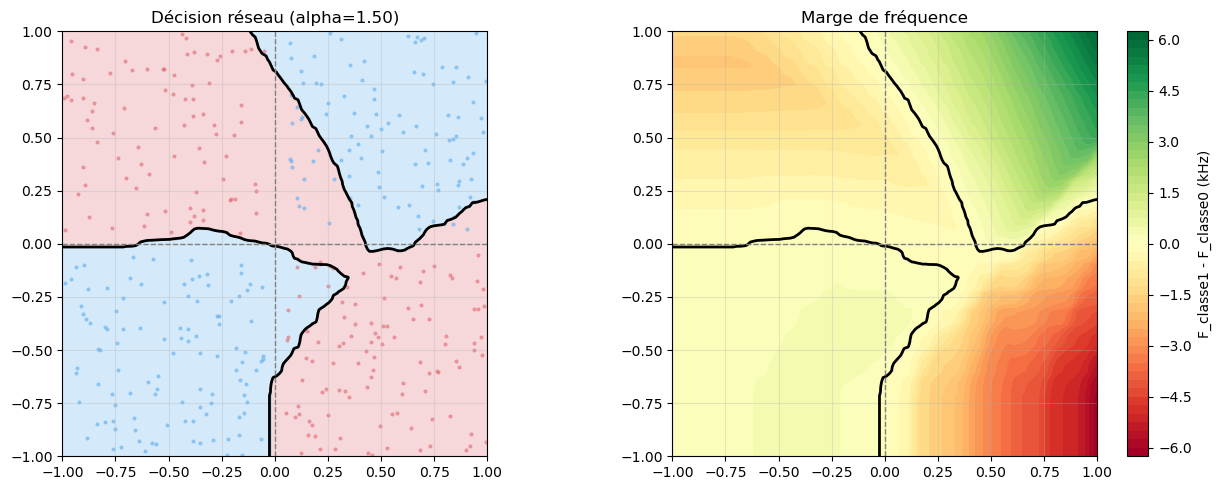

In [57]:
plot_decision_map(signs_A, widths_A, signs_B, widths_B, best_alpha,
                  X_test=X_test, y_test=y_test)